# Buổi E2: Rừng ngẫu nhiên, bagging cộng một mẹo làm cây khác nhau

**Hiện trường.** Một bưu điện cần máy **đọc chữ số viết tay** trên phong bì. Chị Hạnh đã có cây quyết định (đọc nhầm khá nhiều) và bagging (khá hơn). Cô muốn thêm một mẹo nữa để các cây **bớt giống nhau** vì E1 cho thấy các cây hay mắc cùng một kiểu lỗi.

**Mẹo:** khi chia nhánh, mỗi cây chỉ được **bốc ngẫu nhiên một nhóm cột** để chọn, không được xem hết. Cây nào cũng bị "bịt mắt" một phần nên **cây nào cũng khác cây nào**. Gọi là **rừng ngẫu nhiên** (*random forest*).

**Ẩn dụ:** 200 giám khảo, mỗi người chỉ được xem **một phần ngẫu nhiên** tiêu chí chấm điểm, rồi bỏ phiếu. Không ai có thể bị một tiêu chí nổi bật chi phối.

**Mindset của người làm dữ liệu:** mô hình mạnh nhất không phải cái phức tạp nhất mà thường là cái **dễ dùng, ít cần chỉnh, khó làm hỏng**. Rừng ngẫu nhiên là "con dao đa năng" cho dữ liệu dạng bảng.

**Lưu ý:** dữ liệu mẫu để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: cây, bagging và rừng trên chữ số viết tay |
| Chặng 1 | Núm thứ nhất: max_features, mức bịt mắt |
| Chặng 2 | Núm thứ hai: số cây, và OOB báo khi nào đủ |
| Chặng 3 | Phanh an toàn: độ sâu và cỡ lá, đổi điểm lấy tốc độ |
| Chặng 4 | Cột nào quan trọng? Bản đồ nhiệt điểm ảnh |
| Chặng 5 | Mặt trái: độ quan trọng cũng có thể nói dối |

## Chặng 0: Thấy ngay, ba mô hình trên chữ số viết tay

**Câu hỏi:** rừng hơn cây và bagging bao nhiêu?

Dữ liệu: **1797 ảnh chữ số 8×8** (64 cột, mỗi cột là độ đậm một điểm ảnh), 10 nhóm (đã dùng ở C7).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    "single tree": DecisionTreeClassifier(random_state=0),
    "bagging 200": BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=0),
    "random forest 200": RandomForestClassifier(n_estimators=200, random_state=0),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, n_jobs=-1)
    rows.append({"model": name, "CV accuracy": s.mean(), "std": s.std()})
first = pd.DataFrame(rows)
print(first.round(3).to_string(index=False))

            model  CV accuracy   std
      single tree        0.827 0.027
      bagging 200        0.940 0.015
random forest 200        0.975 0.008


**Giải thích từng dòng**

- `RandomForestClassifier(n_estimators=200, random_state=0)`: rừng ngẫu nhiên 200 cây. `n_estimators` là số cây. Cách dùng y hệt các mô hình khác: `fit`, `predict`, `score`.
- `cross_val_score(m, X_train, y_train, cv=cv, n_jobs=-1)`: kiểm định chéo (D1) chỉ trên phần học; `n_jobs=-1` dùng mọi lõi CPU.
- `for name, m in models.items():`: duyệt từng mô hình trong từ điển, đo bằng cùng một cách chia để công bằng.

**Cách đọc.**
- **Con số:** một cây **82,7%**, bagging **94,0%**, rừng **97,5%**.
- **Bức tranh:** từ cây lên bagging là bước nhảy lớn (bỏ phiếu); từ bagging lên rừng nhích thêm nhờ các cây **bớt giống nhau**. Rừng thường là mô hình mạnh đầu tiên nên thử trên dữ liệu dạng bảng.
- **Câu hỏi tiếp:** "bịt mắt" bao nhiêu thì vừa?

**Mang về chặng 0:** rừng = bagging + mỗi lần chia nhánh chỉ xét một nhóm cột ngẫu nhiên.

## Chặng 1: Núm thứ nhất, `max_features`

**Câu hỏi:** mỗi lần chia nhánh, cây được xem bao nhiêu cột?

- `max_features=64` (mọi cột): cây nào cũng thấy hết, **chính là bagging**.
- `max_features="sqrt"` (căn bậc hai của 64, tức 8 cột): mặc định của rừng cho phân loại.
- `max_features=1`: mỗi lần chia chỉ có **1 cột ngẫu nhiên**, cây rất khác nhau nhưng mỗi cây yếu.

Ta quét núm này và đo điểm kiểm định chéo.

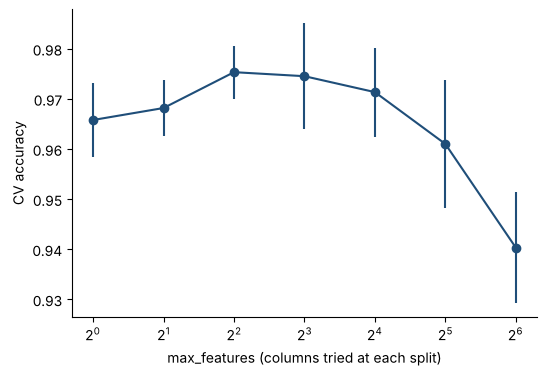

 max_features  CV accuracy   std
            1        0.966 0.007
            2        0.968 0.006
            4        0.975 0.005
            8        0.975 0.011
           16        0.971 0.009
           32        0.961 0.013
           64        0.940 0.011


In [3]:
rows = []
for mf in [1, 2, 4, 8, 16, 32, 64]:
    rf = RandomForestClassifier(n_estimators=150, max_features=mf, random_state=0)
    s = cross_val_score(rf, X_train, y_train, cv=cv, n_jobs=-1)
    rows.append({"max_features": mf, "CV accuracy": s.mean(), "std": s.std()})
mf_table = pd.DataFrame(rows)
fig, ax = plt.subplots()
ax.errorbar(mf_table["max_features"], mf_table["CV accuracy"], yerr=mf_table["std"], color=BLUE, marker="o")
ax.set_xscale("log", base=2); ax.set_xlabel("max_features (columns tried at each split)"); ax.set_ylabel("CV accuracy")
plt.show()
print(mf_table.round(3).to_string(index=False))

**Giải thích từng dòng**

- `max_features=mf`: số cột ngẫu nhiên được xét ở mỗi lần chia nhánh. Số nguyên là số cột; `"sqrt"` là căn bậc hai tổng số cột.
- `ax.errorbar(x, y, yerr=...)`: vẽ điểm kèm thanh sai số (± độ lệch chuẩn giữa các phần).
- `ax.set_xscale("log", base=2)`: trục x theo thang log cơ số 2 vì ta quét 1, 2, 4, 8, ... (gấp đôi mỗi lần).

**Cách đọc.**
- **Con số:** điểm tốt nhất **97,5%** ở `max_features` = **4**; ở 64 (bagging) **94,0%**; ở 1 **96,6%**.
- **Bức tranh:** đường **hình chữ U ngược**: quá ít cột thì mỗi cây yếu, quá nhiều cột thì các cây giống nhau. Vùng quanh căn bậc hai tổng số cột (8) thường đủ tốt, và các thanh sai số cho thấy nhiều giá trị lân cận **không khác nhau rõ rệt**. Mặc định của sklearn là điểm xuất phát hợp lý.

**Mang về chặng 1:** `max_features` đổi giữa "mỗi cây mạnh" và "các cây khác nhau"; thường để mặc định `sqrt` cho phân loại.

## Chặng 2: Núm thứ hai, số cây và OOB

**Câu hỏi:** bao nhiêu cây thì đủ?

Rừng cũng có điểm **OOB** (E1): nhìn nó tiến theo số cây để biết khi nào thôi thêm.

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


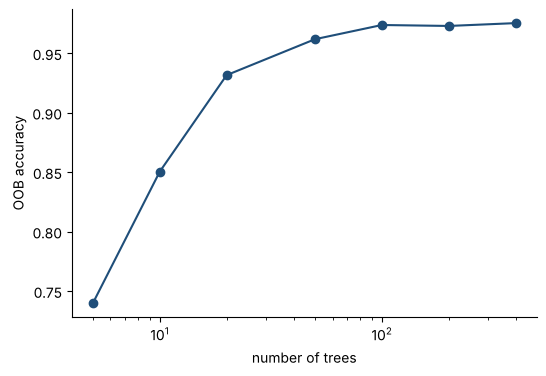

 trees   OOB
     5 0.740
    10 0.850
    20 0.932
    50 0.962
   100 0.974
   200 0.973
   400 0.975


In [4]:
oob_rows = []
for n_trees in [5, 10, 20, 50, 100, 200, 400]:
    rf = RandomForestClassifier(n_estimators=n_trees, oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    oob_rows.append({"trees": n_trees, "OOB": rf.oob_score_})
oob_table = pd.DataFrame(oob_rows)
fig, ax = plt.subplots()
ax.plot(oob_table["trees"], oob_table["OOB"], color=BLUE, marker="o")
ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel("OOB accuracy")
plt.show()
print(oob_table.round(3).to_string(index=False))

**Giải thích từng dòng**

- `RandomForestClassifier(..., oob_score=True)`: với rừng nhỏ (5 cây) một số dòng có thể không bị bỏ ra khỏi cây nào nên sklearn có thể cảnh báo; không ảnh hưởng kết luận.
- `rf.oob_score_`: độ đúng trên các dòng bị bỏ ngoài túi (E1, chặng 3).

**Cách đọc.**
- **Con số:** OOB từ **74,0%** (5 cây) lên **97,4%** (100 cây) và **97,5%** (400 cây).
- **Bức tranh:** tăng nhanh rồi gần phẳng. Từ vài trăm cây trở đi thêm cây chỉ **tốn thời gian và bộ nhớ** mà không đổi điểm. Quy tắc dùng: 100 đến 500 cây; **số cây không gây quá khớp**, nên "nhiều hơn" không hại, chỉ chậm hơn.

**Mang về chặng 2:** số cây tăng đến lúc OOB phẳng là đủ; không có nguy cơ quá khớp vì thêm cây.

## Chặng 3: Phanh an toàn, độ sâu và cỡ lá

**Câu hỏi:** mỗi cây trong rừng nên sâu đến đâu?

Mỗi cây trong rừng mặc định **không giới hạn độ sâu** (vì bỏ phiếu bù lại việc học vẹt). Hai "phanh an toàn" hay dùng khi dữ liệu nhiễu hoặc cần mô hình nhẹ: `max_depth` và `min_samples_leaf` (số dòng tối thiểu trong một lá). Ta đo cả **điểm** và **thời gian huấn luyện**.

In [5]:
import time
rows = []
for label, kw in [("default (unlimited)", {}), ("max_depth=8", {"max_depth": 8}), ("max_depth=4", {"max_depth": 4}), ("min_samples_leaf=5", {"min_samples_leaf": 5}), ("min_samples_leaf=20", {"min_samples_leaf": 20})]:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1, **kw).fit(X_train, y_train)
    rows.append({"setting": label, "train": rf.score(X_train, y_train), "test": rf.score(X_test, y_test), "seconds": time.time() - t0})
brake = pd.DataFrame(rows)
print(brake.round(3).to_string(index=False))

            setting  train  test  seconds
default (unlimited)  1.000 0.978    0.836
        max_depth=8  0.999 0.970    0.778
        max_depth=4  0.941 0.924    0.643
 min_samples_leaf=5  0.992 0.961    0.734
min_samples_leaf=20  0.957 0.937    0.633


**Giải thích từng dòng**

- `**kw`: dấu `**` mở từ điển thành các tham số có tên: `{"max_depth": 8}` thành `max_depth=8`.
- `min_samples_leaf=5`: một lá phải chứa ít nhất 5 dòng: không cho cây tách riêng từng điểm.

**Cách đọc.**
- **Con số:** mặc định: học **100,0%**, thi **97,8%**, 0,80 s. `max_depth=4`: thi **92,4%**, 0,60 s.
- **Bức tranh:** học 100% là bình thường với rừng sâu và **không** có nghĩa là học vẹt có hại (xem điểm thi). Phanh quá gắt (`max_depth=4`) làm cây yếu đi; phanh nhẹ ít đổi điểm. Dùng phanh để **giảm kích thước mô hình** hoặc khi nhãn nhiễu mạnh, không phải vì "sợ quá khớp".
- **Nói thật:** tập thi 540 ảnh, nên chênh lệch dưới 1% có thể chỉ là dao động.

**Mang về chặng 3:** rừng chịu được cây sâu; chỉ dùng phanh khi cần mô hình nhẹ hoặc nhãn nhiễu.

## Chặng 4: Cột nào quan trọng? Bản đồ nhiệt điểm ảnh

**Câu hỏi:** rừng dựa vào điểm ảnh nào để phân biệt chữ số?

Mỗi lần một cây chia nhánh bằng cột nào, nó làm nhóm **thuần hơn** một chút. Cộng dồn mức "thuần hơn" của từng cột qua mọi cây, chuẩn hóa tổng bằng 1, ta có **độ quan trọng** (`feature_importances_`). Vì cột là điểm ảnh, ta vẽ thành ảnh 8×8.

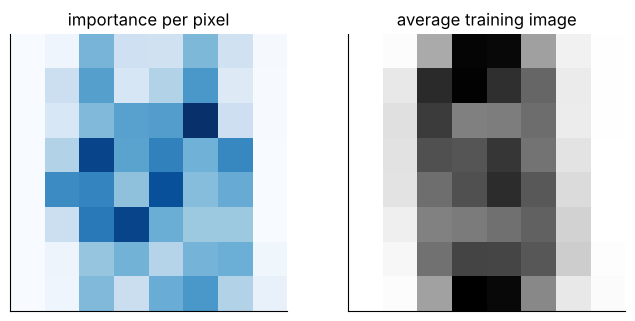

importances sum to: 1.0 | top 5 pixels: [21, 43, 26, 36, 42]


In [6]:
rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_train, y_train)
imp = rf.feature_importances_
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
axes[0].imshow(imp.reshape(8, 8), cmap="Blues"); axes[0].set_title("importance per pixel")
axes[1].imshow(X_train.mean(axis=0).reshape(8, 8), cmap="Greys"); axes[1].set_title("average training image")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.show()
print("importances sum to:", round(imp.sum(), 3), "| top 5 pixels:", np.argsort(imp)[::-1][:5].tolist())

**Giải thích từng dòng**

- `rf.feature_importances_`: mảng 64 số, số thứ i là độ quan trọng của cột i; tổng bằng 1.
- `imp.reshape(8, 8)`: xếp 64 số lại thành lưới 8×8 đúng như vị trí điểm ảnh.
- `np.argsort(imp)[::-1][:5]`: thứ tự cột từ ít đến nhiều quan trọng; `[::-1]` đảo ngược; `[:5]` lấy 5 cột đầu.

**Cách đọc.**
- **Con số:** tổng độ quan trọng bằng **1,00**; 5 điểm ảnh quan trọng nhất có chỉ số [21, 43, 26, 36, 42].
- **Bức tranh:** ở hình trái, vùng **sáng** là chỗ rừng nhìn nhiều nhất, thường ở giữa ảnh nơi nét chữ khác nhau giữa các số; các điểm ảnh ở **viền** (luôn trắng) gần như không có giá trị. Đây là điều hợp lý và dễ kể cho người không rành kỹ thuật.
- **Câu hỏi tiếp:** có tin hoàn toàn vào bảng độ quan trọng này không?

**Mang về chặng 4:** `feature_importances_` cho biết cột nào mô hình dùng nhiều; vẽ ra hình dạng của bài toán nếu cột có vị trí.

## Chặng 5: Mặt trái, độ quan trọng cũng có thể nói dối

**Câu hỏi:** một cột **toàn nhiễu** có thể được rừng coi là quan trọng không?

Thí nghiệm: thêm vào bảng một cột **số ngẫu nhiên liên tục**, vô nghĩa hoàn toàn (dựng có chủ đích), rồi xem rừng gán cho nó bao nhiêu.

In [7]:
rng = np.random.RandomState(0)
X_aug = np.c_[X_train, rng.randn(len(X_train))]
rf_aug = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_aug, y_train)
imp_aug = rf_aug.feature_importances_
rank = int((imp_aug > imp_aug[-1]).sum()) + 1
print("importance of the pure-noise column:", round(imp_aug[-1], 4), "| its rank among 65 columns:", rank)
print("average importance of the 64 real pixels:", round(imp_aug[:-1].mean(), 4))

importance of the pure-noise column: 0.0041 | its rank among 65 columns: 46
average importance of the 64 real pixels: 0.0156


**Giải thích từng dòng**

- `np.c_[X_train, rng.randn(len(X_train))]`: ghép thêm một cột số ngẫu nhiên (phân phối chuẩn) vào cuối bảng.
- `(imp_aug > imp_aug[-1]).sum() + 1`: đếm có bao nhiêu cột quan trọng hơn cột nhiễu rồi cộng 1 ra thứ hạng của nó.

**Cách đọc.**
- **Con số:** cột nhiễu có độ quan trọng **0,0041**, xếp hạng **46/65**; trung bình một điểm ảnh thật **0,0156**.
- **Bức tranh:** cột nhiễu vẫn **được gán một giá trị dương**, vì cây vẫn có thể chia nhánh trên nó theo kiểu "học thuộc nhiễu" trong phần học. Quan trọng hơn: độ quan trọng này đo **mức dùng khi học**, không đo **mức giúp ích khi thi**. **Nói thật:** ở bài này cột nhiễu xếp khá thấp (dưới trung bình), nên rừng phân biệt được khá tốt; nhưng nó **không bằng 0**, và với dữ liệu ít ca hoặc nhiều cột nhiễu liên tục, cột nhiễu có thể leo lên cao hơn.
- **Cách phòng:** đừng đọc `feature_importances_` như sự thật; kiểm tra bằng **độ quan trọng hoán vị** (đo điểm **thi** tụt bao nhiêu khi xáo một cột), nội dung của buổi E6.

**Mang về chặng 5:** độ quan trọng kiểu cây là gợi ý, không phải bằng chứng; kiểm chứng bằng hoán vị.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Rừng = bagging + bốc ngẫu nhiên nhóm cột ở mỗi lần chia; thường mạnh nhất trong ba. |
| 1 | `max_features` đổi giữa cây mạnh và cây khác nhau; mặc định `sqrt` là điểm xuất phát tốt. |
| 2 | Số cây tăng đến khi OOB phẳng; thêm cây không gây quá khớp. |
| 3 | Rừng chịu được cây sâu; phanh để làm mô hình nhẹ hoặc chống nhãn nhiễu. |
| 4 | `feature_importances_` cho biết cột được dùng nhiều; vẽ thành ảnh nếu cột có vị trí. |
| 5 | Độ quan trọng kiểu cây có thể thổi phồng cột nhiễu; kiểm chứng bằng hoán vị. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Nhiều giám khảo, mỗi người một phần tiêu chí | rừng ngẫu nhiên | `RandomForestClassifier` |
| Số giám khảo | số cây | `n_estimators` |
| Phần tiêu chí mỗi người được xem | số cột xét mỗi lần chia | `max_features` |
| Thi thử bằng hồ sơ bị bỏ ngoài | điểm ngoài túi | `oob_score=True`, `oob_score_` |
| Phanh giới hạn độ sâu | độ sâu tối đa | `max_depth` |
| Phanh cỡ lá | số dòng tối thiểu mỗi lá | `min_samples_leaf` |
| Cột nào được dùng nhiều | độ quan trọng (kiểu cây) | `feature_importances_` |

**Thử thách tự làm**

1. Chạy lại chặng 1 với `random_state` khác nhau. Giá trị `max_features` tốt nhất có ổn định không?
2. Thay `RandomForestClassifier` bằng `ExtraTreesClassifier` (chia nhánh ở ngưỡng ngẫu nhiên). Điểm và tốc độ đổi thế nào?
3. Ở chặng 5, thêm 10 cột nhiễu thay vì 1. Thứ hạng của cột nhiễu tốt nhất là bao nhiêu?
4. Dùng `class_weight="balanced"` trong rừng cho một bài toán lệch nhóm (xem C8). Recall của nhóm hiếm đổi thế nào?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích điểm khác giữa bagging và rừng ngẫu nhiên.
- [ ] Chọn `max_features` bằng kiểm định chéo.
- [ ] Dùng điểm OOB để quyết định số cây.
- [ ] Đọc `feature_importances_` và nói được giới hạn của nó.
- [ ] Biết khi nào không cần phanh.

## Phần thưởng (Tip pro): Rừng cho hồi quy và ô trống


`RandomForestRegressor` làm y hệt nhưng trung bình số thay vì bỏ phiếu. Điểm cần nhớ: rừng hồi quy **không ngoại suy** (không đoán được giá trị vượt phạm vi đã thấy, như cây ở D6). Với phiên bản sklearn mới, rừng còn **chấp nhận ô trống (NaN)** trực tiếp, nhưng vẫn nên hiểu vì sao ô trống xuất hiện (B4).